In [6]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')
import glob
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)

sns.set_theme(style="whitegrid")

print("Libraries loaded successfully.")

/kaggle/input/datasets/dhoogla/cicids2017/Benign-Monday-no-metadata.parquet
/kaggle/input/datasets/dhoogla/cicids2017/Bruteforce-Tuesday-no-metadata.parquet
/kaggle/input/datasets/dhoogla/cicids2017/Portscan-Friday-no-metadata.parquet
/kaggle/input/datasets/dhoogla/cicids2017/WebAttacks-Thursday-no-metadata.parquet
/kaggle/input/datasets/dhoogla/cicids2017/DoS-Wednesday-no-metadata.parquet
/kaggle/input/datasets/dhoogla/cicids2017/DDoS-Friday-no-metadata.parquet
/kaggle/input/datasets/dhoogla/cicids2017/Infiltration-Thursday-no-metadata.parquet
/kaggle/input/datasets/dhoogla/cicids2017/Botnet-Friday-no-metadata.parquet
Libraries loaded successfully.


In [7]:
DATA_DIR = Path("/kaggle/input/datasets/dhoogla/cicids2017")

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATA_DIR}\n"
        "Check the path in the Kaggle notebook's Input panel."
    )

all_files = sorted(
    path for path in DATA_DIR.rglob("*")
    if path.is_file()
)

print(f"Dataset directory: {DATA_DIR}")
print(f"Total files: {len(all_files)}")

for path in all_files[:50]:
    print(f"{path.relative_to(DATA_DIR)}  |  {path.stat().st_size / (1024**2):.2f} MB")

if len(all_files) > 50:
    print(f"... and {len(all_files) - 50} more files")

Dataset directory: /kaggle/input/datasets/dhoogla/cicids2017
Total files: 8
Benign-Monday-no-metadata.parquet  |  54.14 MB
Botnet-Friday-no-metadata.parquet  |  18.94 MB
Bruteforce-Tuesday-no-metadata.parquet  |  44.00 MB
DDoS-Friday-no-metadata.parquet  |  24.13 MB
DoS-Wednesday-no-metadata.parquet  |  65.04 MB
Infiltration-Thursday-no-metadata.parquet  |  22.07 MB
Portscan-Friday-no-metadata.parquet  |  12.96 MB
WebAttacks-Thursday-no-metadata.parquet  |  16.84 MB


In [8]:
parquet_files = sorted(DATA_DIR.rglob("*.parquet"))
csv_files = sorted(DATA_DIR.rglob("*.csv"))

if parquet_files:
    DATA_FILES = parquet_files
    FILE_FORMAT = "parquet"
elif csv_files:
    DATA_FILES = csv_files
    FILE_FORMAT = "csv"
else:
    raise FileNotFoundError("No Parquet or CSV files found.")

print(f"Selected format: {FILE_FORMAT}")
print(f"Number of selected files: {len(DATA_FILES)}")

for path in DATA_FILES:
    print(f"- {path.name}")

print(f"\nTotal size: {sum(p.stat().st_size for p in DATA_FILES) / (1024**2):.2f} MB")

Selected format: parquet
Number of selected files: 8
- Benign-Monday-no-metadata.parquet
- Botnet-Friday-no-metadata.parquet
- Bruteforce-Tuesday-no-metadata.parquet
- DDoS-Friday-no-metadata.parquet
- DoS-Wednesday-no-metadata.parquet
- Infiltration-Thursday-no-metadata.parquet
- Portscan-Friday-no-metadata.parquet
- WebAttacks-Thursday-no-metadata.parquet

Total size: 258.12 MB


In [9]:
dataframes = []

for path in DATA_FILES:
    print(f"Loading: {path.name}")

    if FILE_FORMAT == "parquet":
        part = pd.read_parquet(path)
    else:
        part = pd.read_csv(path, low_memory=False)

    # Remove accidental spaces from column names
    part.columns = part.columns.astype(str).str.strip()

    # Track the source file for debugging
    part["_source_file"] = path.name

    print(f"  Shape: {part.shape}")
    dataframes.append(part)

df = pd.concat(dataframes, ignore_index=True, sort=False)

print("\nDataset successfully loaded!")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

Loading: Benign-Monday-no-metadata.parquet
  Shape: (458831, 79)
Loading: Botnet-Friday-no-metadata.parquet
  Shape: (176038, 79)
Loading: Bruteforce-Tuesday-no-metadata.parquet
  Shape: (389714, 79)
Loading: DDoS-Friday-no-metadata.parquet
  Shape: (221264, 79)
Loading: DoS-Wednesday-no-metadata.parquet
  Shape: (584991, 79)
Loading: Infiltration-Thursday-no-metadata.parquet
  Shape: (207630, 79)
Loading: Portscan-Friday-no-metadata.parquet
  Shape: (119522, 79)
Loading: WebAttacks-Thursday-no-metadata.parquet
  Shape: (155820, 79)

Dataset successfully loaded!
Rows: 2,313,810
Columns: 79
Memory usage: 856.29 MB


In [10]:
print("First 5 rows:")
display(df.head())

print("\nDataset dimensions:")
print(df.shape)

print("\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}")

print("\nData types:")
display(df.dtypes.value_counts().rename_axis("Data type").to_frame("Count"))

First 5 rows:


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,_source_file
0,6,4,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,3.000000e+06,5.000000e+05,4.000000,0.000000,4,4,4,4.0,0.000000,4,4,0,0.000000,0.000000,0,0,0,0,0,0,40,0,5.000000e+05,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
1,6,1,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,1.200000e+07,2.000000e+06,1.000000,0.000000,1,1,1,1.0,0.000000,1,1,0,0.000000,0.000000,0,0,0,0,0,0,40,0,2.000000e+06,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
2,6,3,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,4.000000e+06,6.666667e+05,3.000000,0.000000,3,3,3,3.0,0.000000,3,3,0,0.000000,0.000000,0,0,0,0,0,0,40,0,6.666667e+05,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,245,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
3,6,1,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,1.200000e+07,2.000000e+06,1.000000,0.000000,1,1,1,1.0,0.000000,1,1,0,0.000000,0.000000,0,0,0,0,0,0,40,0,2.000000e+06,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,245,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
4,6,609,7,4,484,414,233,0,69.14286,111.967896,207,0,103.5,119.511505,1.474548e+06,1.806240e+04,60.900002,115.194954,381,2,609,101.5,177.089523,460,2,467,155.666672,263.560883,460,3,0,0,0,0,164,104,1.149425e+04,6568.144531,0,233,74.833336,107.527443,11562.151367,0,0,0,1,0,0,0,0,0,81.63636,69.14286,103.5,0,0,0,0,0,0,7,484,4,414,8192,2053,5,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet



Dataset dimensions:
(2313810, 79)

Column names:
01. Protocol
02. Flow Duration
03. Total Fwd Packets
04. Total Backward Packets
05. Fwd Packets Length Total
06. Bwd Packets Length Total
07. Fwd Packet Length Max
08. Fwd Packet Length Min
09. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Bwd PSH Flags
33. Fwd URG Flags
34. Bwd URG Flags
35. Fwd Header Length
36. Bwd Header Length
37. Fwd Packets/s
38. Bwd Packets/s
39. Packet Length Min
40. Packet Length Max
41. Packet Length Mean
42. Packet Length Std
43. Packet Length Variance
44. FIN Flag Count
45. SYN Flag Count
46. RST Flag Count
47. PS

,Count
Data type,
int32,26
float32,22
int8,19
int16,7
float64,2
object,2
int64,1


In [11]:
label_candidates = [
    col for col in df.columns
    if col.strip().lower() in {"label", "class", "attack", "category"}
]

print("Potential label columns:", label_candidates)

if len(label_candidates) != 1:
    raise ValueError(
        "Expected exactly one label column. "
        f"Found: {label_candidates}. Inspect df.columns and select manually."
    )

LABEL_COL = label_candidates[0]

# Normalize label formatting without changing the actual class meanings
df[LABEL_COL] = df[LABEL_COL].astype("string").str.strip()

print(f"\nSelected target column: {LABEL_COL}")
print("\nUnique labels:")
print(df[LABEL_COL].value_counts(dropna=False))

Potential label columns: ['Label']

Selected target column: Label

Unique labels:
Label
Benign                        1977318
DoS Hulk                       172846
DDoS                           128014
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
PortScan                         1956
Web Attack � Brute Force         1470
Bot                              1437
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: Int64


In [12]:
print(f"Total samples: {len(df):,}")
print(f"Total features including label/source: {df.shape[1]:,}")
print(f"Number of classes: {df[LABEL_COL].nunique(dropna=True)}")

class_counts = df[LABEL_COL].value_counts(dropna=False)

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_counts / len(df) * 100
})

display(class_summary.round(3))

Total samples: 2,313,810
Total features including label/source: 79
Number of classes: 15


,Count,Percentage (%)
Label,,
Benign,1977318,85.457
DoS Hulk,172846,7.47
DDoS,128014,5.533
DoS GoldenEye,10286,0.445
FTP-Patator,5931,0.256
DoS slowloris,5385,0.233
DoS Slowhttptest,5228,0.226
SSH-Patator,3219,0.139
PortScan,1956,0.085


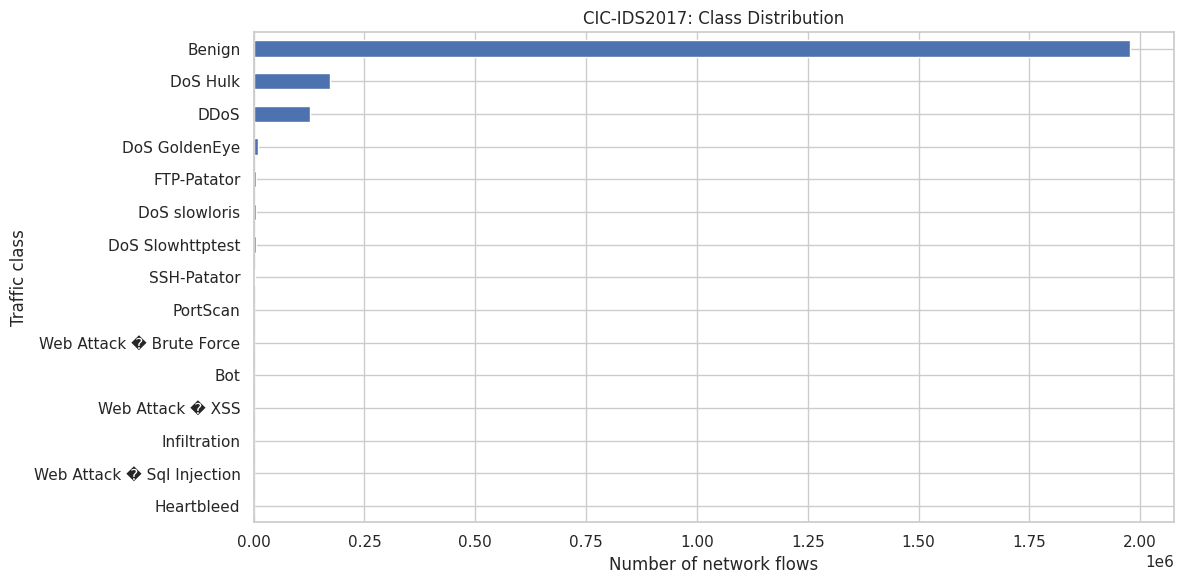

In [13]:
plt.figure(figsize=(12, 6))

class_counts.sort_values().plot(kind="barh")

plt.title("CIC-IDS2017: Class Distribution")
plt.xlabel("Number of network flows")
plt.ylabel("Traffic class")
plt.tight_layout()
plt.show()

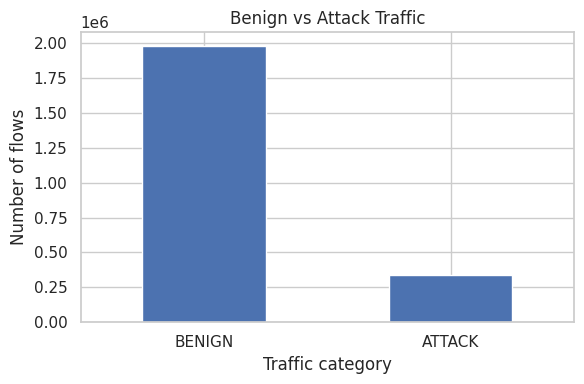

,Count,Percentage (%)
Label,,
BENIGN,1977318,85.457
ATTACK,336492,14.543


In [14]:
binary_labels = (
    df[LABEL_COL]
    .astype("string")
    .str.upper()
    .eq("BENIGN")
    .map({True: "BENIGN", False: "ATTACK"})
)

binary_counts = binary_labels.value_counts()

plt.figure(figsize=(6, 4))
binary_counts.plot(kind="bar")
plt.title("Benign vs Attack Traffic")
plt.xlabel("Traffic category")
plt.ylabel("Number of flows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(
    pd.DataFrame({
        "Count": binary_counts,
        "Percentage (%)": binary_counts / len(df) * 100
    }).round(3)
)

In [15]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Columns containing missing values:", len(missing))

if len(missing):
    display(missing.to_frame("Missing values"))
else:
    print("No missing values found.")

numeric_df = df.select_dtypes(include=np.number)

infinite_counts = pd.Series(
    np.isinf(numeric_df.to_numpy()).sum(axis=0),
    index=numeric_df.columns
)

infinite_counts = infinite_counts[infinite_counts > 0].sort_values(
    ascending=False
)

print("\nColumns containing infinite values:", len(infinite_counts))

if len(infinite_counts):
    display(infinite_counts.to_frame("Infinite values"))
else:
    print("No infinite values found.")

Columns containing missing values: 0
No missing values found.

Columns containing infinite values: 0
No infinite values found.


In [16]:
# Exclude the bookkeeping column from the duplicate comparison
comparison_cols = [
    col for col in df.columns
    if col != "_source_file"
]

duplicate_mask = df.duplicated(subset=comparison_cols, keep=False)

print(f"Rows belonging to duplicate groups: {duplicate_mask.sum():,}")
print(f"Rows that are exact duplicates after the first occurrence: "
      f"{df.duplicated(subset=comparison_cols).sum():,}")

if duplicate_mask.any():
    display(df.loc[duplicate_mask].head(10))

Rows belonging to duplicate groups: 131,375
Rows that are exact duplicates after the first occurrence: 82,004


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,_source_file
26,6,4,2,0,12,0,6,6,6.0,0.000000,0,0,0.0,0.0,3000000.0,500000.0,4.0,0.0,4,4,4,4.0,0.0,4,4,0,0.0,0.0,0,0,0,0,0,0,40,0,500000.0,0.0,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,0,0,0,0,0,0,2,12,0,0,255,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
36,6,1,2,0,7,0,7,0,3.5,4.949748,0,0,0.0,0.0,7000000.0,2000000.0,1.0,0.0,1,1,1,1.0,0.0,1,1,0,0.0,0.0,0,0,1,0,0,0,64,0,2000000.0,0.0,0,7,4.666667,4.041452,16.333334,0,1,0,0,1,0,0,0,0,7.0,3.5,0.0,0,0,0,0,0,0,2,7,0,0,237,-1,0,32,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
64,6,1,2,0,39,0,39,0,19.5,27.577164,0,0,0.0,0.0,39000000.0,2000000.0,1.0,0.0,1,1,1,1.0,0.0,1,1,0,0.0,0.0,0,0,1,0,0,0,64,0,2000000.0,0.0,0,39,26.000000,22.516661,507.000000,0,1,0,0,1,0,0,0,0,39.0,19.5,0.0,0,0,0,0,0,0,2,39,0,0,245,-1,0,32,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
67,6,1,2,0,37,0,31,6,18.5,17.677670,0,0,0.0,0.0,37000000.0,2000000.0,1.0,0.0,1,1,1,1.0,0.0,1,1,0,0.0,0.0,0,0,1,0,0,0,40,0,2000000.0,0.0,6,31,22.666666,14.433757,208.333328,0,1,0,0,1,0,0,0,0,34.0,18.5,0.0,0,0,0,0,0,0,2,37,0,0,1013,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
270,17,4,2,0,124,0,62,62,62.0,0.000000,0,0,0.0,0.0,31000000.0,500000.0,4.0,0.0,4,4,4,4.0,0.0,4,4,0,0.0,0.0,0,0,0,0,0,0,64,0,500000.0,0.0,62,62,62.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,0,93.0,62.0,0.0,0,0,0,0,0,0,2,124,0,0,-1,-1,1,32,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
323,6,4,2,0,12,0,6,6,6.0,0.000000,0,0,0.0,0.0,3000000.0,500000.0,4.0,0.0,4,4,4,4.0,0.0,4,4,0,0.0,0.0,0,0,0,0,0,0,40,0,500000.0,0.0,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,0,0,0,0,0,0,2,12,0,0,256,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
478,6,4,2,0,37,0,31,6,18.5,17.677670,0,0,0.0,0.0,9250000.0,500000.0,4.0,0.0,4,4,4,4.0,0.0,4,4,0,0.0,0.0,0,0,1,0,0,0,40,0,500000.0,0.0,6,31,22.666666,14.433757,208.333328,0,1,0,0,1,0,0,0,0,34.0,18.5,0.0,0,0,0,0,0,0,2,37,0,0,980,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
479,6,10,1,1,6,6,6,6,6.0,0.000000,6,6,6.0,0.0,1200000.0,200000.0,10.0,0.0,10,10,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,100000.0,100000.0,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,1,9.0,6.0,6.0,0,0,0,0,0,0,1,6,1,6,255,946,0,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
482,6,4,2,0,12,0,6,6,6.0,0.000000,0,0,0.0,0.0,3000000.0,500000.0,4.0,0.0,4,4,4,4.0,0.0,4,4,0,0.0,0.0,0,0,0,0,0,0,40,0,500000.0,0.0,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,0,0,0,0,0,0,2,12,0,0,360,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
539,6,4,2,0,37,0,31,6,18.5,17.677670,0,0,0.0,0.0,9250000.0,

In [17]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

print(f"Number of numerical columns: {len(numeric_cols)}")
print("\nDescriptive statistics:")

display(df[numeric_cols].describe().T)

Number of numerical columns: 77

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Protocol,2313810.0,1.050673e+01,5.416040e+00,0.000000e+00,6.000000,6.000000,1.700000e+01,1.700000e+01
Flow Duration,2313810.0,1.807575e+07,3.640823e+07,-1.300000e+01,476.000000,64783.000000,5.856948e+06,1.200000e+08
Total Fwd Packets,2313810.0,1.108391e+01,8.291879e+02,1.000000e+00,2.000000,2.000000,6.000000e+00,2.197590e+05
Total Backward Packets,2313810.0,1.255334e+01,1.103179e+03,0.000000e+00,1.000000,2.000000,5.000000e+00,2.919220e+05
Fwd Packets Length Total,2313810.0,6.664045e+02,1.105009e+04,0.000000e+00,37.000000,74.000000,3.560000e+02,1.290000e+07
Bwd Packets Length Total,2313810.0,1.976976e+04,2.503141e+06,0.000000e+00,26.000000,183.000000,2.306000e+03,6.554530e+08
Fwd Packet Length Max,2313810.0,2.506291e+02,7.855073e+02,0.000000e+00,20.000000,43.000000,2.740000e+02,2.482000e+04
Fwd Packet Length Min,2313810.0,2.142396e+01,6.334192e+01,0.000000e+00,0.000000,6.000000,3.900000e+01,2.325000e+03
Fwd Packet Length Mean,2313810.0,6.880502e+01,2.017213e+02,0.000000e+00,8.666667,39.555557,5.400000e+01,5.940857e+03
Fwd Packet Length Std,2313810.0,8.299153e+01,3.041364e+02,0.000000e+00,0.000000,0.000000,8.499406e+01,7.125597e+03


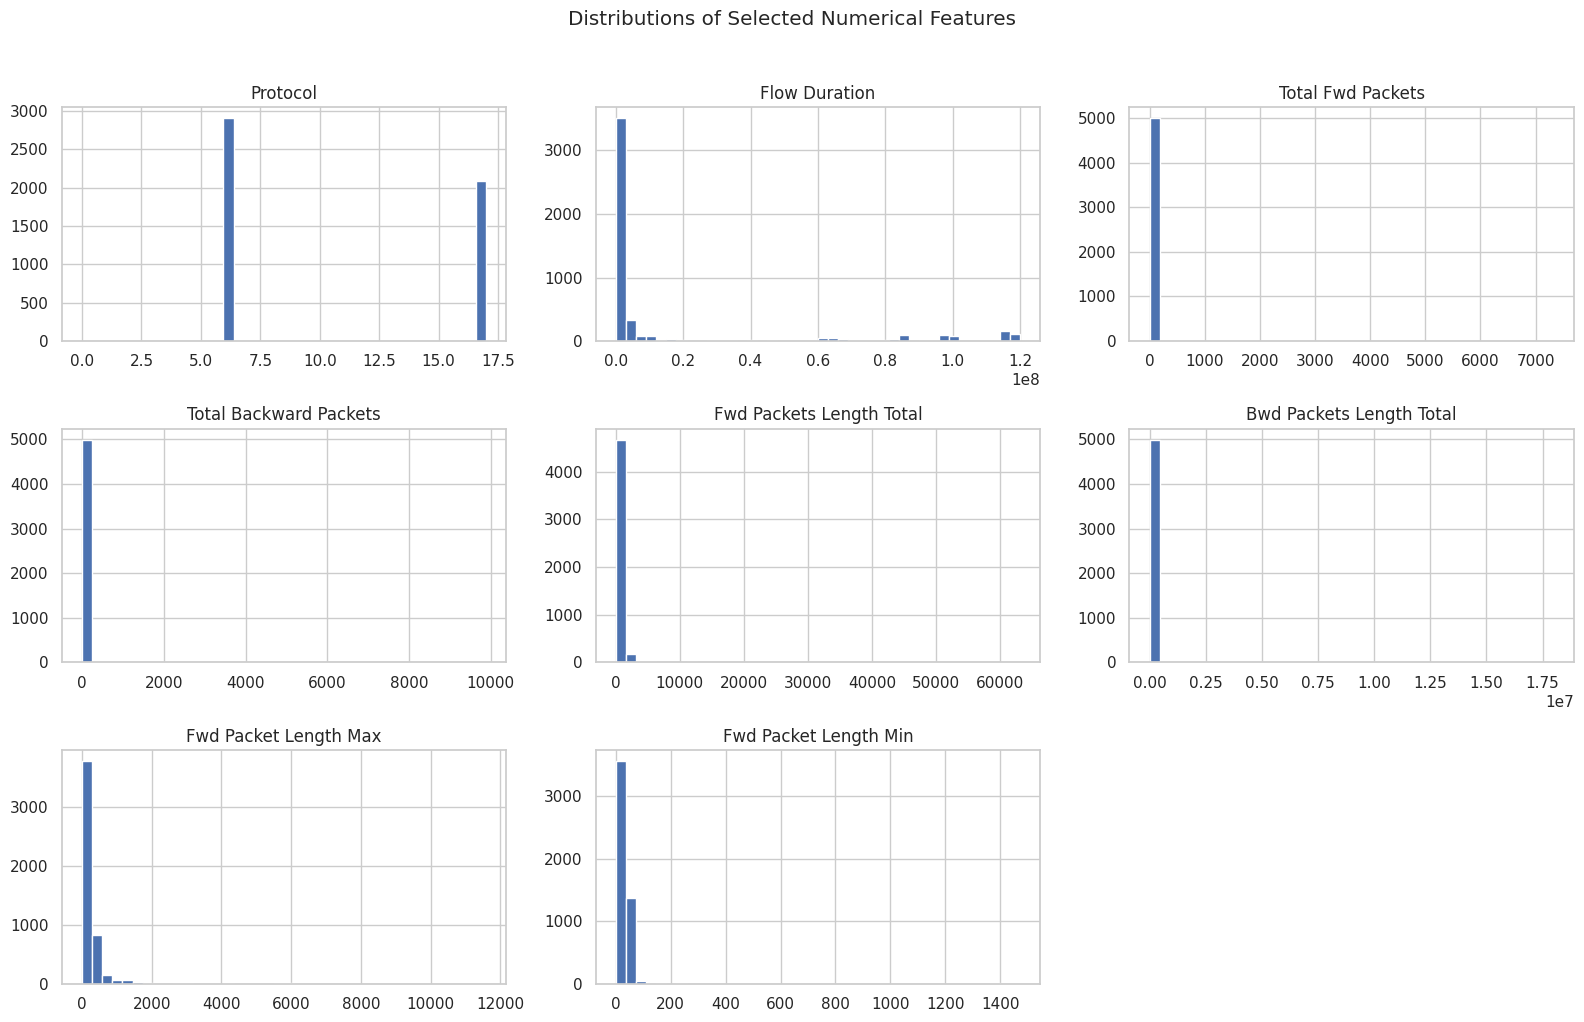

In [18]:
# Select a manageable sample of numerical features for visualization
plot_features = numeric_cols[:8]

if plot_features:
    df[plot_features].sample(
        n=min(5000, len(df)),
        random_state=42
    ).hist(
        bins=40,
        figsize=(16, 10),
        layout=(-1, 3)
    )

    plt.suptitle("Distributions of Selected Numerical Features", y=1.02)
    plt.tight_layout()
    plt.show()

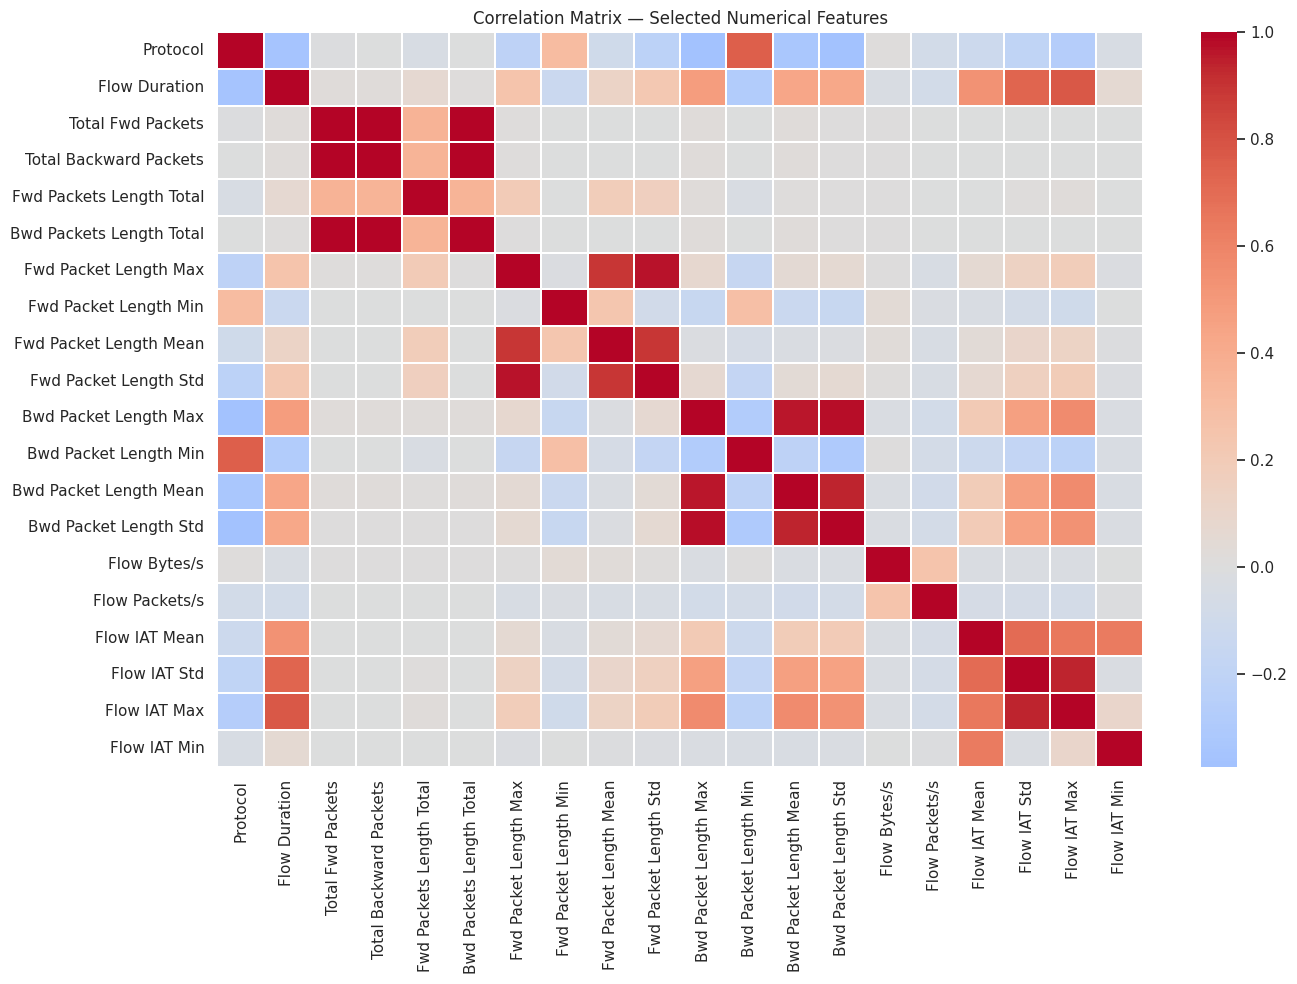

In [19]:
# Limit the plot to a manageable number of numerical features
corr_features = numeric_cols[:20]

if len(corr_features) >= 2:
    corr_matrix = df[corr_features].corr()

    plt.figure(figsize=(14, 10))
    sns.heatmap(
        corr_matrix,
        cmap="coolwarm",
        center=0,
        linewidths=0.2
    )

    plt.title("Correlation Matrix — Selected Numerical Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical features for a correlation matrix.")

In [20]:
OUTPUT_DIR = Path("/kaggle/working/eda_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

class_summary.to_csv(OUTPUT_DIR / "class_distribution.csv")
df.dtypes.astype(str).rename("dtype").to_csv(
    OUTPUT_DIR / "data_types.csv"
)
df.head(100).to_csv(OUTPUT_DIR / "sample_rows.csv", index=False)

print("EDA summaries saved to:", OUTPUT_DIR)
print("\nGenerated files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)

EDA summaries saved to: /kaggle/working/eda_results

Generated files:
- class_distribution.csv
- data_types.csv
- sample_rows.csv


In [21]:
%pip install -q imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

print("Preprocessing libraries ready.")

Preprocessing libraries ready.


In [23]:
assert "df" in globals(), "Run the dataset-loading cells first."

df = df.copy()
df.columns = df.columns.astype(str).str.strip()

LABEL_COL = "Label"

if LABEL_COL not in df.columns:
    raise ValueError(f"Label column not found. Columns: {df.columns.tolist()}")

df[LABEL_COL] = df[LABEL_COL].astype("string").str.strip()

# Remove rows with missing target labels
df = df.dropna(subset=[LABEL_COL]).copy()

# Remove source-file bookkeeping; it is not a model feature
df = df.drop(columns=["_source_file"], errors="ignore")

# Preserve multiclass labels for future experiments
df["Original_Label"] = df[LABEL_COL]

# Binary target for the first supervised baseline
df["Target"] = (
    df[LABEL_COL]
    .str.casefold()
    .eq("benign")
    .map({True: "BENIGN", False: "ATTACK"})
)

print("Dataset shape:", df.shape)
print("\nOriginal labels:")
display(df["Original_Label"].value_counts().to_frame("Count"))

print("\nBinary target:")
display(df["Target"].value_counts().to_frame("Count"))

Dataset shape: (2313810, 80)

Original labels:


,Count
Original_Label,
Benign,1977318
DoS Hulk,172846
DDoS,128014
DoS GoldenEye,10286
FTP-Patator,5931
DoS slowloris,5385
DoS Slowhttptest,5228
SSH-Patator,3219
PortScan,1956



Binary target:


,Count
Target,
BENIGN,1977318
ATTACK,336492


In [24]:
excluded_cols = [LABEL_COL, "Original_Label", "Target"]

feature_cols = [
    col for col in df.columns
    if col not in excluded_cols
]

# Convert invalid numeric entries to NaN
X = df[feature_cols].apply(pd.to_numeric, errors="coerce")

# Infinite flow rates can occur when duration is zero
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns that are entirely missing
all_missing = X.columns[X.isna().all()].tolist()

if all_missing:
    print("Removing entirely missing columns:", all_missing)
    X = X.drop(columns=all_missing)

# Remove constant columns
constant_cols = X.columns[X.nunique(dropna=True) <= 1].tolist()

if constant_cols:
    print("Removing constant columns:", constant_cols)
    X = X.drop(columns=constant_cols)

y = df["Target"].copy()

print("\nFeature matrix:", X.shape)
print("Target vector:", y.shape)
print("Missing feature values:", int(X.isna().sum().sum()))
print("Infinite feature values:", int(np.isinf(X.to_numpy()).sum()))

Removing constant columns: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Feature matrix: (2313810, 69)
Target vector: (2313810,)
Missing feature values: 0
Infinite feature values: 0


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining distribution:")
display(y_train.value_counts().to_frame("Count"))

print("\nTest distribution:")
display(y_test.value_counts().to_frame("Count"))

Training set: (1851048, 69)
Test set: (462762, 69)

Training distribution:


,Count
Target,
BENIGN,1581854
ATTACK,269194



Test distribution:


,Count
Target,
BENIGN,395464
ATTACK,67298


In [26]:
MAX_BENIGN = 150_000

train_frame = X_train.copy()
train_frame["Target"] = y_train

benign_train = train_frame[train_frame["Target"] == "BENIGN"]
attack_train = train_frame[train_frame["Target"] == "ATTACK"]

if len(benign_train) > MAX_BENIGN:
    benign_train = benign_train.sample(
        n=MAX_BENIGN,
        random_state=RANDOM_STATE
    )

train_sample = pd.concat(
    [benign_train, attack_train],
    axis=0
).sample(frac=1, random_state=RANDOM_STATE)

X_train_sample = train_sample.drop(columns="Target")
y_train_sample = train_sample["Target"]

print("Sampled training shape:", X_train_sample.shape)
display(y_train_sample.value_counts().to_frame("Count"))

Sampled training shape: (419194, 69)


,Count
Target,
ATTACK,269194
BENIGN,150000


In [27]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imputed = imputer.fit_transform(X_train_sample)
X_test_imputed = imputer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Training matrix:", X_train_scaled.shape)
print("Test matrix:", X_test_scaled.shape)

print("Remaining NaN in training:", np.isnan(X_train_scaled).sum())
print("Remaining NaN in test:", np.isnan(X_test_scaled).sum())

Training matrix: (419194, 69)
Test matrix: (462762, 69)
Remaining NaN in training: 0
Remaining NaN in test: 0


In [28]:
smote = SMOTE(
    sampling_strategy="auto",
    random_state=RANDOM_STATE,
    k_neighbors=5
)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled,
    y_train_sample
)

print("Before SMOTE:")
display(y_train_sample.value_counts().to_frame("Count"))

print("\nAfter SMOTE:")
display(pd.Series(y_train_balanced).value_counts().to_frame("Count"))

print("\nBalanced feature matrix:", X_train_balanced.shape)

Before SMOTE:


,Count
Target,
ATTACK,269194
BENIGN,150000



After SMOTE:


,Count
Target,
ATTACK,269194
BENIGN,269194



Balanced feature matrix: (538388, 69)


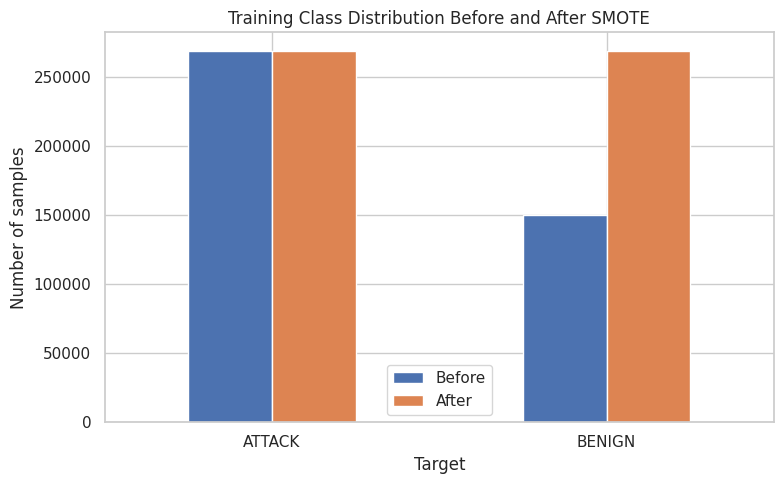

In [29]:
before = y_train_sample.value_counts().rename("Before")
after = pd.Series(y_train_balanced).value_counts().rename("After")

comparison = pd.concat([before, after], axis=1).fillna(0)

comparison.plot(kind="bar", figsize=(8, 5))
plt.title("Training Class Distribution Before and After SMOTE")
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [30]:
import joblib
from pathlib import Path

ARTIFACT_DIR = Path("/kaggle/working/preprocessing_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(imputer, ARTIFACT_DIR / "imputer.joblib")
joblib.dump(scaler, ARTIFACT_DIR / "scaler.joblib")

joblib.dump(feature_cols, ARTIFACT_DIR / "feature_columns.joblib")

print("Saved artifacts to:", ARTIFACT_DIR)

Saved artifacts to: /kaggle/working/preprocessing_artifacts


In [31]:
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
LABEL_COL = "Label"

assert "df" in globals(), "Run the data-loading and EDA cells first."

raw_df = df.copy()
raw_df.columns = raw_df.columns.astype(str).str.strip()

if LABEL_COL not in raw_df.columns:
    raise ValueError(f"Missing target column: {LABEL_COL}")

raw_df[LABEL_COL] = raw_df[LABEL_COL].astype("string").str.strip()
raw_df = raw_df.dropna(subset=[LABEL_COL]).copy()

# Keep original labels for future multiclass experiments
raw_df["Original_Label"] = raw_df[LABEL_COL]

# Binary classification target
raw_df["Target"] = (
    raw_df[LABEL_COL].str.casefold()
    .eq("benign")
    .map({True: 0, False: 1})
    .astype("int8")
)

# Remove known bookkeeping columns
raw_df = raw_df.drop(columns=["_source_file"], errors="ignore")

print("Raw dataset shape:", raw_df.shape)
print("\nBinary labels: 0 = BENIGN, 1 = ATTACK")
print(raw_df["Target"].value_counts())

Raw dataset shape: (2313810, 80)

Binary labels: 0 = BENIGN, 1 = ATTACK
Target
0    1977318
1     336492
Name: count, dtype: int64


In [32]:
TARGET_COLS = {"Label", "Original_Label", "Target"}

feature_candidates = [
    c for c in raw_df.columns
    if c not in TARGET_COLS
]

# Numeric features only for our first model
X_raw = raw_df[feature_candidates].copy()

for col in X_raw.columns:
    X_raw[col] = pd.to_numeric(X_raw[col], errors="coerce")

X_raw = X_raw.replace([np.inf, -np.inf], np.nan)

column_audit = pd.DataFrame({
    "dtype": X_raw.dtypes.astype(str),
    "missing_pct": X_raw.isna().mean().mul(100),
    "unique_values": X_raw.nunique(dropna=True),
})

column_audit["all_missing"] = column_audit["unique_values"].eq(0)
column_audit["constant"] = column_audit["unique_values"].le(1)

# Flag suspicious identifiers; review before removing
column_audit["review_flag"] = [
    "identifier/time review"
    if any(token in col.lower() for token in
           ["flow id", "timestamp", "source ip", "destination ip",
            "src ip", "dst ip", "source port", "destination port"])
    else ""
    for col in column_audit.index
]

display(column_audit.sort_values(
    ["review_flag", "missing_pct"],
    ascending=[False, False]
))

,dtype,missing_pct,unique_values,all_missing,constant,review_flag
Protocol,int8,0.0,3,False,False,
Flow Duration,int32,0.0,1050898,False,False,
Total Fwd Packets,int32,0.0,1432,False,False,
Total Backward Packets,int32,0.0,1747,False,False,
Fwd Packets Length Total,int32,0.0,17928,False,False,
Bwd Packets Length Total,int32,0.0,64698,False,False,
Fwd Packet Length Max,int16,0.0,5279,False,False,
Fwd Packet Length Min,int16,0.0,384,False,False,
Fwd Packet Length Mean,float32,0.0,85557,False,False,
Fwd Packet Length Std,float32,0.0,241199,False,False,


In [33]:
def find_column(data, *candidates):
    """Find a column using case-insensitive, whitespace-insensitive matching."""
    normalized = {
        str(c).strip().lower(): c
        for c in data.columns
    }

    for candidate in candidates:
        key = candidate.strip().lower()
        if key in normalized:
            return normalized[key]

    return None


X_engineered = X_raw.copy()

duration_col = find_column(
    X_engineered, "Flow Duration"
)
fwd_packets_col = find_column(
    X_engineered, "Total Fwd Packets"
)
bwd_packets_col = find_column(
    X_engineered, "Total Backward Packets"
)
fwd_bytes_col = find_column(
    X_engineered, "Total Length of Fwd Packets"
)
bwd_bytes_col = find_column(
    X_engineered, "Total Length of Bwd Packets"
)

def safe_ratio(numerator, denominator):
    """Calculate a ratio while avoiding division by zero."""
    denominator = denominator.replace(0, np.nan)
    return numerator / denominator

created_features = []

# Forward/backward packet ratio
if fwd_packets_col and bwd_packets_col:
    X_engineered["FE_Fwd_Bwd_Packet_Ratio"] = safe_ratio(
        X_engineered[fwd_packets_col],
        X_engineered[bwd_packets_col]
    )
    created_features.append("FE_Fwd_Bwd_Packet_Ratio")

# Forward/backward byte ratio
if fwd_bytes_col and bwd_bytes_col:
    X_engineered["FE_Fwd_Bwd_Byte_Ratio"] = safe_ratio(
        X_engineered[fwd_bytes_col],
        X_engineered[bwd_bytes_col]
    )
    created_features.append("FE_Fwd_Bwd_Byte_Ratio")

# Log transformation of flow duration
if duration_col:
    X_engineered["FE_Log_Flow_Duration"] = np.log1p(
        X_engineered[duration_col].clip(lower=0)
    )
    created_features.append("FE_Log_Flow_Duration")

# Log transformations of packet and byte counts
for col in [fwd_packets_col, bwd_packets_col,
            fwd_bytes_col, bwd_bytes_col]:
    if col:
        new_col = "FE_Log_" + col.replace(" ", "_")
        X_engineered[new_col] = np.log1p(
            X_engineered[col].clip(lower=0)
        )
        created_features.append(new_col)

X_engineered = X_engineered.replace([np.inf, -np.inf], np.nan)

print("Original numeric features:", X_raw.shape[1])
print("New features created:", len(created_features))
print(created_features)
print("Engineered feature matrix:", X_engineered.shape)

Original numeric features: 77
New features created: 4
['FE_Fwd_Bwd_Packet_Ratio', 'FE_Log_Flow_Duration', 'FE_Log_Total_Fwd_Packets', 'FE_Log_Total_Backward_Packets']
Engineered feature matrix: (2313810, 81)


In [34]:
y = raw_df["Target"].copy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_engineered,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training:", X_train_raw.shape)
print("Testing:", X_test_raw.shape)

print("\nTraining labels:")
display(y_train.value_counts().rename("count").to_frame())

print("\nTesting labels:")
display(y_test.value_counts().rename("count").to_frame())

Training: (1851048, 81)
Testing: (462762, 81)

Training labels:


,count
Target,
0,1581854
1,269194



Testing labels:


,count
Target,
0,395464
1,67298


In [35]:
all_missing_cols = X_train_raw.columns[
    X_train_raw.isna().all()
].tolist()

X_train_raw = X_train_raw.drop(columns=all_missing_cols)
X_test_raw = X_test_raw.drop(columns=all_missing_cols)

constant_cols = X_train_raw.columns[
    X_train_raw.nunique(dropna=True) <= 1
].tolist()

X_train_raw = X_train_raw.drop(columns=constant_cols)
X_test_raw = X_test_raw.drop(columns=constant_cols)

print("All-missing columns removed:", all_missing_cols)
print("Constant columns removed:", constant_cols)
print("Remaining features:", X_train_raw.shape[1])

All-missing columns removed: []
Constant columns removed: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Remaining features: 73


In [36]:
CORRELATION_THRESHOLD = 0.98

# A bounded sample keeps correlation analysis manageable
corr_sample = X_train_raw.sample(
    n=min(100_000, len(X_train_raw)),
    random_state=RANDOM_STATE
)

corr_matrix = corr_sample.corr().abs()

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
    .rename(columns={
        "level_0": "Feature_1",
        "level_1": "Feature_2",
        0: "Absolute_Correlation"
    })
    .query("Absolute_Correlation >= @CORRELATION_THRESHOLD")
    .sort_values("Absolute_Correlation", ascending=False)
)

print("Highly correlated pairs:", len(high_corr_pairs))
display(high_corr_pairs.head(50))

Highly correlated pairs: 36


,Feature_1,Feature_2,Absolute_Correlation
187,Total Fwd Packets,Subflow Fwd Packets,1.000000
572,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000
811,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000
256,Total Backward Packets,Subflow Bwd Packets,1.000000
1675,Fwd PSH Flags,SYN Flag Count,1.000000
321,Fwd Packets Length Total,Subflow Fwd Bytes,1.000000
388,Bwd Packets Length Total,Subflow Bwd Bytes,1.000000
1705,Fwd Header Length,Bwd Header Length,0.999978
141,Total Fwd Packets,Bwd Packets Length Total,0.999846
385,Bwd Packets Length Total,Subflow Fwd Packets,0.999846


Selected features: 30


,Importance
Bwd Packet Length Mean,0.073187
Packet Length Std,0.064779
Avg Bwd Segment Size,0.062021
Protocol,0.055355
Bwd Packet Length Max,0.046033
Packet Length Mean,0.042207
Avg Packet Size,0.039357
Bwd Packet Length Std,0.037060
Idle Min,0.034468
FE_Log_Flow_Duration,0.028960


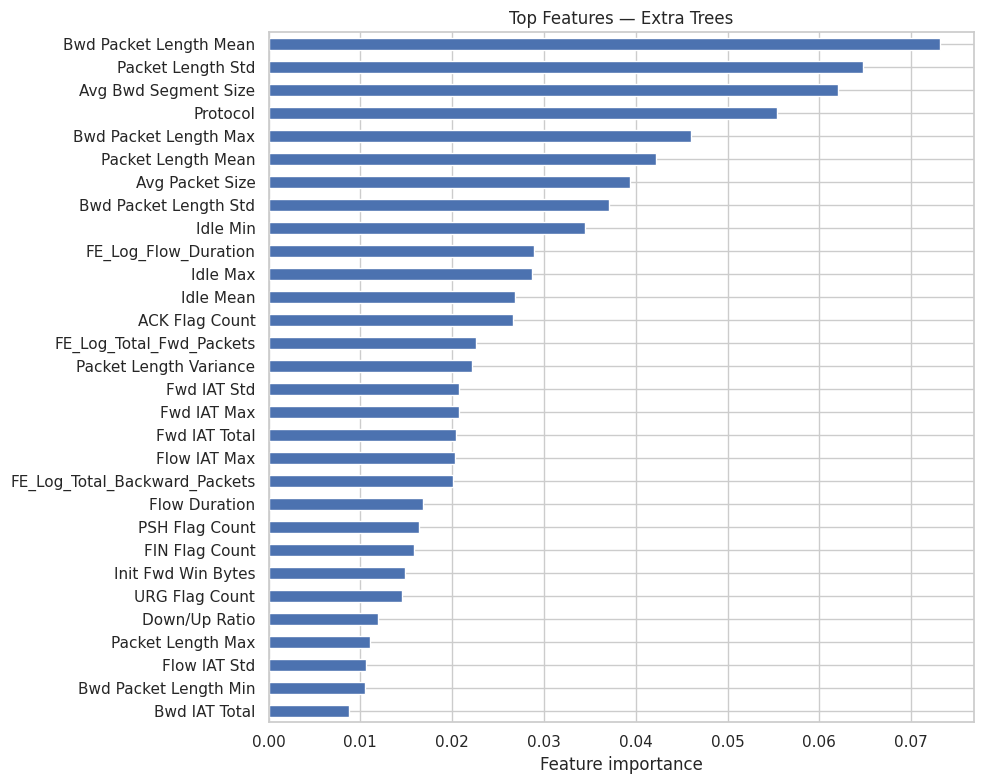

In [37]:
from sklearn.ensemble import ExtraTreesClassifier

MAX_SELECTION_SAMPLES = 100_000
MAX_SELECTED_FEATURES = 30

selection_n = min(MAX_SELECTION_SAMPLES, len(X_train_raw))

selection_idx = X_train_raw.sample(
    n=selection_n,
    random_state=RANDOM_STATE
).index

X_selection = X_train_raw.loc[selection_idx].copy()
y_selection = y_train.loc[selection_idx].copy()

# Fit imputation on the feature-selection sample only
from sklearn.impute import SimpleImputer

selection_imputer = SimpleImputer(strategy="median")

X_selection_imp = selection_imputer.fit_transform(X_selection)

selector_model = ExtraTreesClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

selector_model.fit(X_selection_imp, y_selection)

importance = pd.Series(
    selector_model.feature_importances_,
    index=X_selection.columns
).sort_values(ascending=False)

selected_features = importance.head(
    min(MAX_SELECTED_FEATURES, len(importance))
).index.tolist()

print("Selected features:", len(selected_features))
display(importance.head(MAX_SELECTED_FEATURES).to_frame("Importance"))

plt.figure(figsize=(10, 8))
importance.head(MAX_SELECTED_FEATURES).sort_values().plot(kind="barh")
plt.title("Top Features — Extra Trees")
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

In [38]:
from sklearn.preprocessing import StandardScaler

X_train_selected = X_train_raw[selected_features].copy()
X_test_selected = X_test_raw[selected_features].copy()

final_imputer = SimpleImputer(strategy="median")
final_scaler = StandardScaler()

X_train_imputed = final_imputer.fit_transform(X_train_selected)
X_test_imputed = final_imputer.transform(X_test_selected)

X_train_final = final_scaler.fit_transform(X_train_imputed)
X_test_final = final_scaler.transform(X_test_imputed)

print("Final training matrix:", X_train_final.shape)
print("Final test matrix:", X_test_final.shape)

assert X_train_final.shape[1] == X_test_final.shape[1]
assert np.isfinite(X_train_final).all()
assert np.isfinite(X_test_final).all()

print("No NaN or infinite values remain.")

Final training matrix: (1851048, 30)
Final test matrix: (462762, 30)
No NaN or infinite values remain.


In [39]:
import joblib

ARTIFACT_DIR = Path("/kaggle/working/feature_engineering")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(selected_features, ARTIFACT_DIR / "selected_features.joblib")
joblib.dump(final_imputer, ARTIFACT_DIR / "imputer.joblib")
joblib.dump(final_scaler, ARTIFACT_DIR / "scaler.joblib")
joblib.dump(selector_model, ARTIFACT_DIR / "feature_selector_model.joblib")

importance.to_csv(ARTIFACT_DIR / "feature_importance.csv")

print("Artifacts saved to:", ARTIFACT_DIR)

Artifacts saved to: /kaggle/working/feature_engineering


In [40]:
# Final readiness checks

assert X_train_final.shape[1] == X_test_final.shape[1]
assert len(X_train_final) == len(y_train)
assert len(X_test_final) == len(y_test)

assert np.isfinite(X_train_final).all()
assert np.isfinite(X_test_final).all()

assert set(np.unique(y_train)) == {0, 1}
assert set(np.unique(y_test)) == {0, 1}

print("Training shape:", X_train_final.shape)
print("Testing shape:", X_test_final.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

print("\nSelected features:")
print(selected_features)

print("\nAll basic readiness checks passed.")

Training shape: (1851048, 30)
Testing shape: (462762, 30)

Training class distribution:
Target
0    1581854
1     269194
Name: count, dtype: int64

Testing class distribution:
Target
0    395464
1     67298
Name: count, dtype: int64

Selected features:
['Bwd Packet Length Mean', 'Packet Length Std', 'Avg Bwd Segment Size', 'Protocol', 'Bwd Packet Length Max', 'Packet Length Mean', 'Avg Packet Size', 'Bwd Packet Length Std', 'Idle Min', 'FE_Log_Flow_Duration', 'Idle Max', 'Idle Mean', 'ACK Flag Count', 'FE_Log_Total_Fwd_Packets', 'Packet Length Variance', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Total', 'Flow IAT Max', 'FE_Log_Total_Backward_Packets', 'Flow Duration', 'PSH Flag Count', 'FIN Flag Count', 'Init Fwd Win Bytes', 'URG Flag Count', 'Down/Up Ratio', 'Packet Length Max', 'Flow IAT Std', 'Bwd Packet Length Min', 'Bwd IAT Total']

All basic readiness checks passed.


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Use feature-engineering outputs if SMOTE was applied to this same pipeline.
# Otherwise, resample X_train_final below.
print("Feature-engineered training:", X_train_final.shape)
print("Feature-engineered test:", X_test_final.shape)

assert X_train_final.shape[1] == X_test_final.shape[1]
assert len(X_train_final) == len(y_train)
assert len(X_test_final) == len(y_test)

print("\nOriginal training labels:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest labels:")
print(pd.Series(y_test).value_counts().sort_index())

Feature-engineered training: (1851048, 30)
Feature-engineered test: (462762, 30)

Original training labels:
Target
0    1581854
1     269194
Name: count, dtype: int64

Test labels:
Target
0    395464
1     67298
Name: count, dtype: int64


In [42]:
from imblearn.over_sampling import SMOTE

# Use a manageable sample for a first neural-network experiment.
# Keep all attacks and sample benign flows to control RAM use.
MAX_BENIGN = 300_000

X_train_array = np.asarray(X_train_final, dtype=np.float32)
y_train_array = np.asarray(y_train, dtype=np.int32)

benign_idx = np.where(y_train_array == 0)[0]
attack_idx = np.where(y_train_array == 1)[0]

rng = np.random.default_rng(SEED)

if len(benign_idx) > MAX_BENIGN:
    benign_idx = rng.choice(
        benign_idx,
        size=MAX_BENIGN,
        replace=False
    )

train_idx = np.concatenate([benign_idx, attack_idx])
rng.shuffle(train_idx)

X_train_subset = X_train_array[train_idx]
y_train_subset = y_train_array[train_idx]

print("Before SMOTE:", X_train_subset.shape)
print(pd.Series(y_train_subset).value_counts().sort_index())

smote = SMOTE(random_state=SEED, k_neighbors=5)

X_train_balanced_nn, y_train_balanced_nn = smote.fit_resample(
    X_train_subset,
    y_train_subset
)

X_train_balanced_nn = np.asarray(
    X_train_balanced_nn, dtype=np.float32
)
y_train_balanced_nn = np.asarray(
    y_train_balanced_nn, dtype=np.float32
)

X_test_nn = np.asarray(X_test_final, dtype=np.float32)
y_test_nn = np.asarray(y_test, dtype=np.int32)

print("\nAfter SMOTE:", X_train_balanced_nn.shape)
print(pd.Series(y_train_balanced_nn).value_counts().sort_index())

Before SMOTE: (569194, 30)
0    300000
1    269194
Name: count, dtype: int64

After SMOTE: (600000, 30)
0.0    300000
1.0    300000
Name: count, dtype: int64


In [43]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_balanced_nn,
    y_train_balanced_nn,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train_balanced_nn
)

print("Model training set:", X_fit.shape)
print("Validation set:", X_val.shape)
print("Final test set:", X_test_nn.shape)

Model training set: (510000, 30)
Validation set: (90000, 30)
Final test set: (462762, 30)


In [44]:
n_features = X_fit.shape[1]

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(n_features,)),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.30),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.20),

    tf.keras.layers.Dense(32, activation="relu"),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.AUC(name="pr_auc", curve="PR")
    ]
)

model.summary()

2026-10-18 16:14:13.553580: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,105 (59.00 KB)

 Trainable params: 14,721 (57.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [45]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

start_time = time.time()

history = model.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=1024,
    callbacks=callbacks,
    verbose=1
)

training_seconds = time.time() - start_time

print(f"\nTraining time: {training_seconds:.2f} seconds")
print(f"Epochs completed: {len(history.history['loss'])}")

Epoch 1/30
499/499 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9623 - loss: 0.0955 - pr_auc: 0.9945 - precision: 0.9667 - recall: 0.9575 - roc_auc: 0.9940 - val_accuracy: 0.9792 - val_loss: 0.0496 - val_pr_auc: 0.9986 - val_precision: 0.9904 - val_recall: 0.9678 - val_roc_auc: 0.9985 - learning_rate: 0.0010
Epoch 2/30
499/499 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9806 - loss: 0.0517 - pr_auc: 0.9980 - precision: 0.9843 - recall: 0.9768 - roc_auc: 0.9980 - val_accuracy: 0.9864 - val_loss: 0.0372 - val_pr_auc: 0.9989 - val_precision: 0.9922 - val_recall: 0.9806 - val_roc_auc: 0.9989 - learning_rate: 0.0010
Epoch 3/30
499/499 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9840 - loss: 0.0430 - pr_auc: 0.9984 - precision: 0.9879 - recall: 0.9801 - roc_auc: 0.9985 - val_accuracy: 0.9884 - val_loss: 0.0321 - val_pr_auc: 0.9991 - val_precision: 0.9948 - val_recall: 0.9819 - val_roc_auc: 0.9991 - learning_rate: 0.0010
Epoch 4/30
499/499 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accura

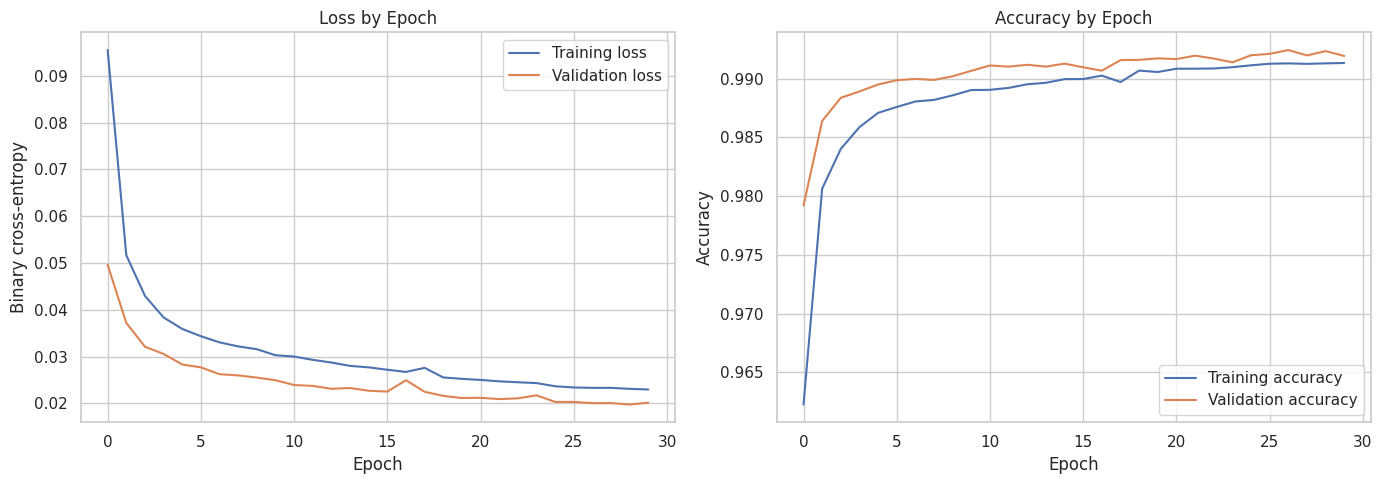

In [46]:
history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_df["loss"], label="Training loss")
axes[0].plot(history_df["val_loss"], label="Validation loss")
axes[0].set_title("Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy")
axes[0].legend()

axes[1].plot(history_df["accuracy"], label="Training accuracy")
axes[1].plot(history_df["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Accuracy by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [47]:
start_time = time.time()

y_probability = model.predict(
    X_test_nn,
    batch_size=4096,
    verbose=1
).ravel()

inference_seconds = time.time() - start_time

# Default classification threshold
THRESHOLD = 0.50
y_pred = (y_probability >= THRESHOLD).astype(int)

accuracy = accuracy_score(y_test_nn, y_pred)
precision = precision_score(y_test_nn, y_pred, zero_division=0)
recall = recall_score(y_test_nn, y_pred, zero_division=0)
f1 = f1_score(y_test_nn, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test_nn, y_probability)
pr_auc = average_precision_score(y_test_nn, y_probability)

tn, fp, fn, tp = confusion_matrix(
    y_test_nn, y_pred, labels=[0, 1]
).ravel()

false_positive_rate = fp / (fp + tn) if (fp + tn) else 0
specificity = tn / (tn + fp) if (tn + fp) else 0

metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Attack recall",
        "F1-score",
        "ROC-AUC",
        "PR-AUC (average precision)",
        "Specificity",
        "False-positive rate"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        pr_auc,
        specificity,
        false_positive_rate
    ]
})

display(metrics.style.format({"Score": "{:.4f}"}))

print(f"\nInference time: {inference_seconds:.2f} seconds")
print(f"Average per flow: {inference_seconds / len(y_test_nn) * 1000:.4f} ms")

113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


,Metric,Score
0,Accuracy,0.9953
1,Precision,0.9806
2,Attack recall,0.9874
3,F1-score,0.9840
4,ROC-AUC,0.9997
5,PR-AUC (average precision),0.9985
6,Specificity,0.9967
7,False-positive rate,0.0033



Inference time: 0.86 seconds
Average per flow: 0.0019 ms


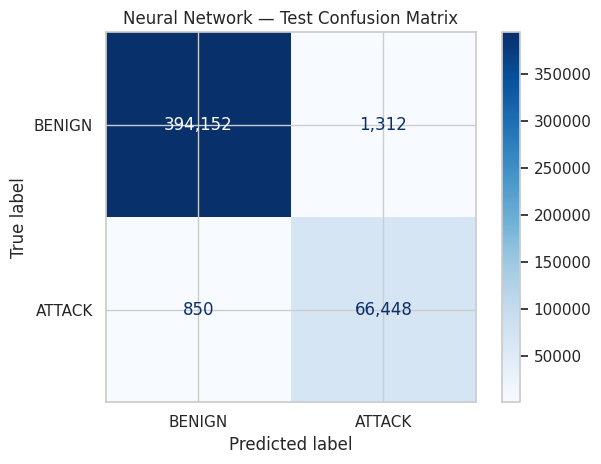

              precision    recall  f1-score   support

      BENIGN     0.9978    0.9967    0.9973    395464
      ATTACK     0.9806    0.9874    0.9840     67298

    accuracy                         0.9953    462762
   macro avg     0.9892    0.9920    0.9906    462762
weighted avg     0.9953    0.9953    0.9953    462762



In [48]:
cm = confusion_matrix(y_test_nn, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
)

disp.plot(cmap="Blues", values_format=",")
plt.title("Neural Network — Test Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test_nn,
    y_pred,
    labels=[0, 1],
    target_names=["BENIGN", "ATTACK"],
    digits=4,
    zero_division=0
))

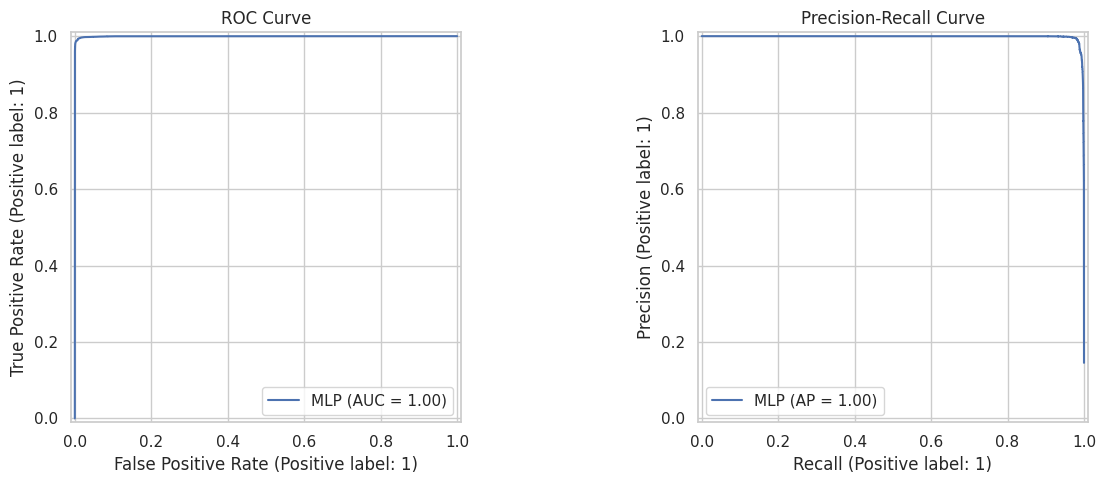

In [49]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(
    y_test_nn,
    y_probability,
    ax=axes[0],
    name="MLP"
)
axes[0].set_title("ROC Curve")

PrecisionRecallDisplay.from_predictions(
    y_test_nn,
    y_probability,
    ax=axes[1],
    name="MLP"
)
axes[1].set_title("Precision-Recall Curve")

plt.tight_layout()
plt.show()

In [50]:
print("=== FIREWALL MODEL EVALUATION ===")
print(f"Accuracy:            {accuracy:.2%}")
print(f"Attack detection:    {recall:.2%}")
print(f"Precision:           {precision:.2%}")
print(f"F1-score:            {f1:.4f}")
print(f"False-positive rate: {false_positive_rate:.2%}")
print(f"ROC-AUC:             {roc_auc:.4f}")
print(f"PR-AUC:              {pr_auc:.4f}")

if false_positive_rate > 0.05:
    print("\nWarning: false-positive rate exceeds 5%.")
    print("Tune the decision threshold before considering automatic blocking.")

if recall < 0.90:
    print("\nWarning: attack recall is below 90%.")
    print("Inspect class-specific errors and feature quality.")

print("\nDo not enable automatic IP blocking based only on this offline evaluation.")

=== FIREWALL MODEL EVALUATION ===
Accuracy:            99.53%
Attack detection:    98.74%
Precision:           98.06%
F1-score:            0.9840
False-positive rate: 0.33%
ROC-AUC:             0.9997
PR-AUC:              0.9985

Do not enable automatic IP blocking based only on this offline evaluation.


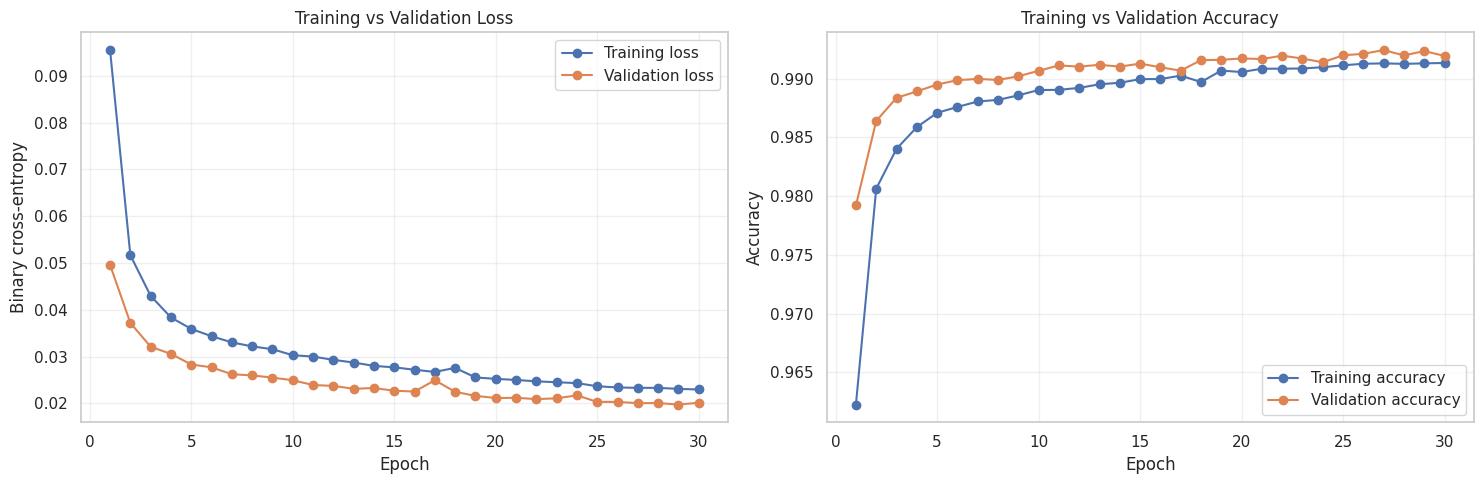

In [51]:
history_df = pd.DataFrame(history.history)
epochs = np.arange(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss curves
axes[0].plot(epochs, history_df["loss"], marker="o", label="Training loss")
axes[0].plot(epochs, history_df["val_loss"], marker="o", label="Validation loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy curves
axes[1].plot(epochs, history_df["accuracy"], marker="o", label="Training accuracy")
axes[1].plot(epochs, history_df["val_accuracy"], marker="o", label="Validation accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [52]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

def evaluate_split(name, X, y):
    probabilities = model.predict(X, batch_size=4096, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    return {
        "Dataset": name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "F1": f1_score(y, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y, probabilities),
        "PR-AUC": average_precision_score(y, probabilities)
    }

# Evaluate on the data actually used for gradient updates
train_metrics = evaluate_split("Training (SMOTE)", X_fit, y_fit)

# Validation data was held out from gradient updates, but is SMOTE-derived
val_metrics = evaluate_split("Validation (SMOTE)", X_val, y_val)

# Original, imbalanced test data
test_metrics = evaluate_split("Test (original distribution)", X_test_nn, y_test_nn)

comparison = pd.DataFrame([
    train_metrics, val_metrics, test_metrics
]).set_index("Dataset")

display(comparison.style.format("{:.4f}"))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Dataset,,,,,,
Training (SMOTE),0.9925,0.9968,0.9882,0.9925,0.9997,0.9997
Validation (SMOTE),0.9923,0.9965,0.9882,0.9923,0.9997,0.9997
Test (original distribution),0.9953,0.9806,0.9874,0.9840,0.9997,0.9985


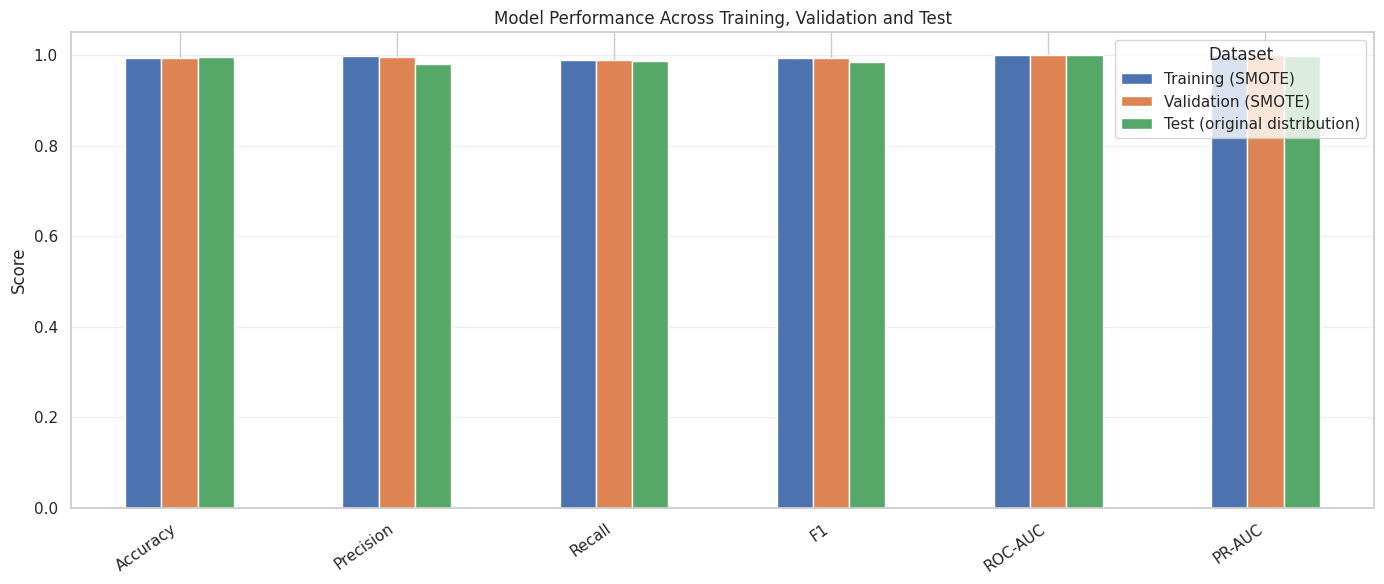

Training-validation gaps:
Accuracy  : +0.0002
Precision : +0.0003
Recall    : +0.0001
F1        : +0.0002
ROC-AUC   : +0.0000
PR-AUC    : +0.0000


In [53]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]

comparison[metrics_to_plot].T.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Model Performance Across Training, Validation and Test")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.legend(title="Dataset")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Training-validation gaps:")
for metric in metrics_to_plot:
    gap = train_metrics[metric] - val_metrics[metric]
    print(f"{metric:10s}: {gap:+.4f}")

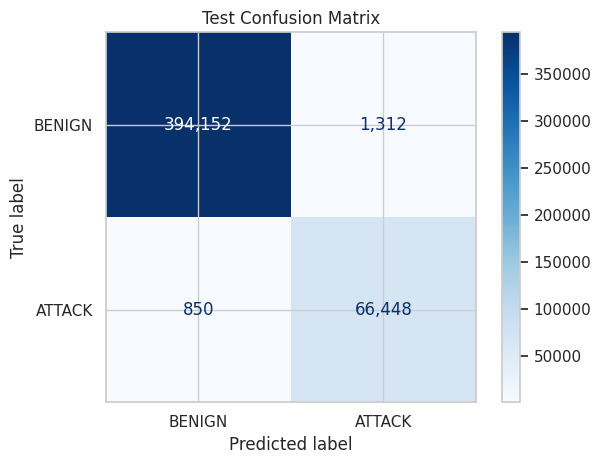

True negatives:  394,152
False positives: 1,312
False negatives: 850
True positives:  66,448


In [54]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

test_probabilities = model.predict(
    X_test_nn, batch_size=4096, verbose=0
).ravel()

test_predictions = (test_probabilities >= 0.5).astype(int)

cm = confusion_matrix(
    y_test_nn, test_predictions, labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
)

disp.plot(cmap="Blues", values_format=",")
plt.title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print(f"True negatives:  {tn:,}")
print(f"False positives: {fp:,}")
print(f"False negatives: {fn:,}")
print(f"True positives:  {tp:,}")

In [55]:
# Use the selected, unscaled features if available
# This is more interpretable than comparing scaled floating-point arrays.

train_raw = X_train_selected.copy()
test_raw = X_test_selected.copy()

train_hashes = pd.util.hash_pandas_object(
    train_raw, index=False
)
test_hashes = pd.util.hash_pandas_object(
    test_raw, index=False
)

train_hash_set = set(train_hashes.to_numpy())

overlap_count = test_hashes.isin(train_hash_set).sum()

print(f"Test rows with a matching training feature hash: {overlap_count:,}")
print(f"Percentage of test rows: {overlap_count / len(test_raw):.4%}")

Test rows with a matching training feature hash: 56,267
Percentage of test rows: 12.1589%


In [56]:

# CELL 1 — Export the trained IDS model and preprocessing artifacts

import os
import json
import joblib
import zipfile
import numpy as np
import tensorflow as tf
from pathlib import Path
from datetime import datetime, timezone

# Create the export directory
EXPORT_DIR = Path("/kaggle/working/ids_firewall_export")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save the trained neural network
model_path = EXPORT_DIR / "ids_model.keras"
model.save(model_path)

print(f"Model saved: {model_path}")
print(f"Model size: {model_path.stat().st_size / (1024**2):.2f} MB")

# 2. Save fitted preprocessing objects
# These must be the objects fitted during your existing preprocessing pipeline.
preprocessing = {}

if "final_imputer" in globals():
    preprocessing["imputer"] = final_imputer

if "final_scaler" in globals():
    preprocessing["scaler"] = final_scaler

if "selected_features" in globals():
    preprocessing["selected_features"] = list(selected_features)

if "feature_names_selected" in globals():
    preprocessing["selected_features"] = list(feature_names_selected)

if not preprocessing:
    print("WARNING: No preprocessing objects were found.")
    print("Check the variable names used in your preprocessing notebook.")

preprocessing_path = EXPORT_DIR / "preprocessing.pkl"
joblib.dump(preprocessing, preprocessing_path)

print(f"Preprocessing saved: {preprocessing_path}")
print("Saved components:", list(preprocessing.keys()))

# 3. Save deployment metadata
n_features = int(model.input_shape[-1])

metadata = {
    "project": "AI-Driven Network Intrusion Detection Firewall",
    "model_type": "TensorFlow/Keras binary classification MLP",
    "input_features": n_features,
    "input_shape": [None, n_features],
    "output": {
        "0": "BENIGN",
        "1": "ATTACK"
    },
    "classification_threshold": 0.5,
    "training_epochs_completed": len(history.history["loss"]),
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "preprocessing_artifact": "preprocessing.pkl",
    "model_artifact": "ids_model.keras"
}

metadata_path = EXPORT_DIR / "metadata.json"
with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print(f"Metadata saved: {metadata_path}")

# 4. List the exported artifacts
print("\nExport directory contents:")
for path in sorted(EXPORT_DIR.iterdir()):
    print(f"  {path.name:25s} {path.stat().st_size / (1024**2):8.2f} MB")


Model saved: /kaggle/working/ids_firewall_export/ids_model.keras
Model size: 0.22 MB
Preprocessing saved: /kaggle/working/ids_firewall_export/preprocessing.pkl
Saved components: ['imputer', 'scaler', 'selected_features']
Metadata saved: /kaggle/working/ids_firewall_export/metadata.json

Export directory contents:
  ids_model.keras               0.22 MB
  metadata.json                 0.00 MB
  preprocessing.pkl             0.00 MB


In [57]:

# CELL 2 — Reload and verify prediction consistency

import numpy as np
import tensorflow as tf
import joblib

reloaded_model = tf.keras.models.load_model(
    "/kaggle/working/ids_firewall_export/ids_model.keras"
)

reloaded_preprocessing = joblib.load(
    "/kaggle/working/ids_firewall_export/preprocessing.pkl"
)

# Use the already-preprocessed test data for this verification.
# Do not apply the imputer/scaler again to X_test_nn.
sample_size = min(1000, len(X_test_nn))
X_sample = np.asarray(X_test_nn[:sample_size], dtype=np.float32)

original_probs = model.predict(X_sample, verbose=0).ravel()
reloaded_probs = reloaded_model.predict(X_sample, verbose=0).ravel()

max_difference = float(
    np.max(np.abs(original_probs - reloaded_probs))
)

print("Original model input shape:", model.input_shape)
print("Reloaded model input shape:", reloaded_model.input_shape)
print(f"Maximum probability difference: {max_difference:.10f}")

assert reloaded_model.input_shape == model.input_shape
assert np.allclose(original_probs, reloaded_probs, atol=1e-6)

print("\nSUCCESS: Saved model reproduces the original predictions.")


Original model input shape: (None, 30)
Reloaded model input shape: (None, 30)
Maximum probability difference: 0.0000000000

SUCCESS: Saved model reproduces the original predictions.


In [58]:

# CELL 3 — Package artifacts for download and transfer

import zipfile
from pathlib import Path

EXPORT_DIR = Path("/kaggle/working/ids_firewall_export")
ZIP_PATH = Path("/kaggle/working/ids_firewall_export.zip")

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in EXPORT_DIR.iterdir():
        if path.is_file():
            archive.write(path, arcname=path.name)

print("Deployment package created:")
print(ZIP_PATH)
print(f"Archive size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")


Deployment package created:
/kaggle/working/ids_firewall_export.zip
Archive size: 0.17 MB
